<!-- Dr. Nam H. Le. drnamlabs.com, bunnyquant.com -->
# 02. Two-population mean field, and is the transition sharp?

Notebook 01 found that the one-size mean field (every stored pattern has the same size m) predicts a fold
that the real bank does not show. The flaw: a real bank keeps fresh outside samples at **full size**,
and only the self-written points shrink.

**Story.** The library again, but now we track two kinds of books separately: originals brought in from outside,
which stay sharp, and copies the library made itself, which are blurred. A reader who arrives with a question
is pulled toward whichever kind dominates near the question.

**The model.** In 1-D, a fraction α of the bank sits at the outside clusters ±1, and 1 − α are self-written copies at ±a.
A query arrives at +1 and is relaxed by attention:

  x ← [ α sinh(βx) + (1 − α) a sinh(βax) ] / [ α cosh(βx) + (1 − α) cosh(βax) ]

Call the limit A(a). Self-writes store A(a), so the stationary copies satisfy **a = A(a)**.
The landscape is alive (K\* = 2) when a > 0.

*Example.* β = 2, α = 0.6. Starting from a dead bank (a = 0), the query at +1 is held by the 60% outside points and
settles at 0.80. Copies are written there, which pulls the next query further out, and a climbs to 0.91.

Then: the finite-size sweep (`sweep_K.py`). K ∈ {20, 40, 80}, β ∈ {2, 4}, 14 values of α,
starting dead or alive, 10 seeds, 300 generations each.

In [1]:
# Dr. Nam H. Le. drnamlabs.com, bunnyquant.com
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
FIG = Path('figures')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

def attract(a, al, b, x=1.0, it=800):
    for _ in range(it):
        xn = (al * np.sinh(b * x) + (1 - al) * a * np.sinh(b * a * x)) / (al * np.cosh(b * x) + (1 - al) * np.cosh(b * a * x))
        if abs(xn - x) < 1e-13:
            break
        x = xn
    return xn

def stationary(al, b, a0, eta=0.1, T=3000):
    a = a0
    for _ in range(T):
        a = (1 - eta) * a + eta * attract(a, al, b)
    return a

def roots(al, b, n=1001):
    ag = np.linspace(0, 1, n)
    G = np.array([attract(a, al, b) - a for a in ag])
    out = []
    for i in range(n - 1):
        if G[i] * G[i + 1] < 0:
            out.append((ag[i], G[i] > G[i + 1]))
    return out

## The cobweb of a = A(a): one picture per regime

For β = 4, the curve A(a) (the attractor a query reaches when the copies sit at a) is drawn for three values of α.
Where it crosses the diagonal, the copies are stationary.

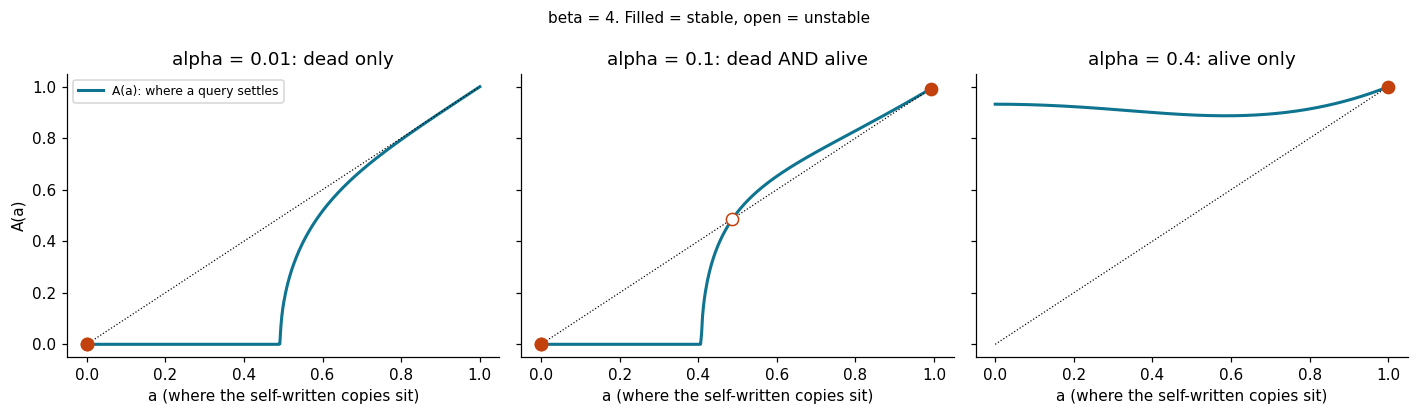

In [2]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
ag = np.linspace(0, 1, 400)
for axi, al, ttl in zip(ax, [0.01, 0.1, 0.4], ['alpha = 0.01: dead only', 'alpha = 0.1: dead AND alive', 'alpha = 0.4: alive only']):
    A = [attract(a, al, 4.0) for a in ag]
    axi.plot(ag, A, color='#0e7490', lw=2, label='A(a): where a query settles')
    axi.plot(ag, ag, 'k:', lw=0.8)
    for r, st in roots(al, 4.0):
        axi.plot(r, r, 'o', color='#c2410c' if st else 'white', mec='#c2410c', ms=8)
    if abs(attract(0, al, 4.0)) < 1e-6:
        axi.plot(0, 0, 'o', color='#c2410c', ms=8)
    axi.set(xlabel='a (where the self-written copies sit)', title=ttl)
ax[0].set_ylabel('A(a)'); ax[0].legend(fontsize=8)
fig.suptitle('beta = 4. Filled = stable, open = unstable', fontsize=10)
fig.tight_layout(); fig.savefig(FIG / 'nb02_cobweb_twopop.png'); plt.show()

## Bifurcation diagram and phase diagram (two-population mean field)

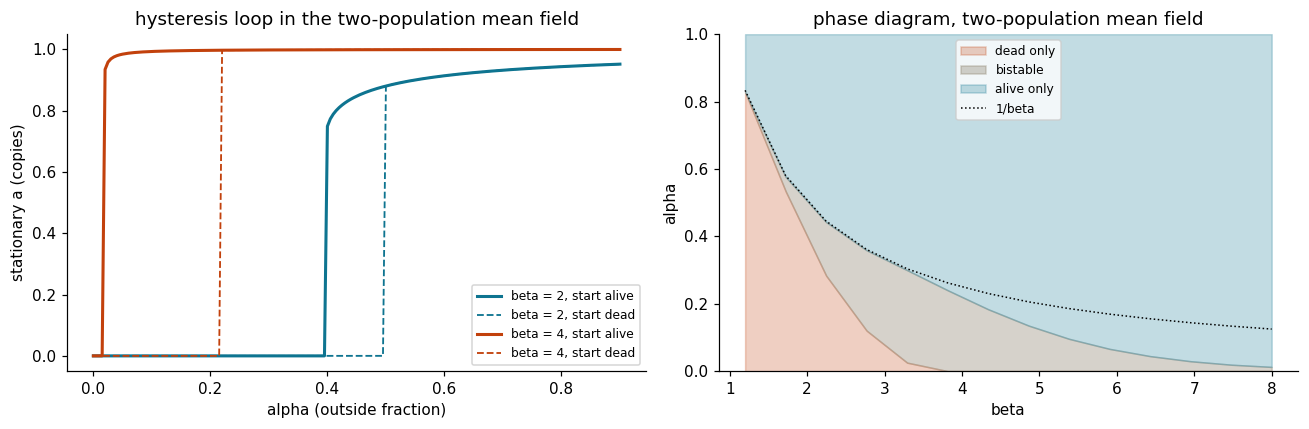

beta=2.0: revive above alpha=0.497, keep alive above alpha=0.392


beta=4.0: revive above alpha=0.220, keep alive above alpha=0.000


In [3]:
alphas_f = np.linspace(0.0, 0.9, 181)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for b, c in zip([2.0, 4.0], ['#0e7490', '#c2410c']):
    dead = [stationary(al, b, 0.0) for al in alphas_f]
    alive = [stationary(al, b, 1.0) for al in alphas_f]
    ax[0].plot(alphas_f, alive, color=c, lw=2, label=f'beta = {b:g}, start alive')
    ax[0].plot(alphas_f, dead, color=c, lw=1.2, ls='--', label=f'beta = {b:g}, start dead')
ax[0].set(xlabel='alpha (outside fraction)', ylabel='stationary a (copies)', title='hysteresis loop in the two-population mean field')
ax[0].legend(fontsize=8)

bs = np.linspace(1.2, 8, 14)
def edge(b, a0):
    lo, hi = 0.0, 1.0           # bisection on the alpha at which the start-a0 bank is alive
    for _ in range(12):
        mid = (lo + hi) / 2
        if stationary(mid, b, a0, T=500) > 1e-3:
            hi = mid
        else:
            lo = mid
    return hi
a_rev = np.array([edge(b, 0.0) for b in bs])
a_keep = np.array([edge(b, 1.0) for b in bs])
ax[1].fill_between(bs, 0, a_keep, color='#c2410c', alpha=0.25, label='dead only')
ax[1].fill_between(bs, a_keep, a_rev, color='#8a7f6a', alpha=0.35, label='bistable')
ax[1].fill_between(bs, a_rev, 1, color='#0e7490', alpha=0.25, label='alive only')
ax[1].plot(bs, 1 / bs, 'k:', lw=1, label='1/beta')
ax[1].set(xlabel='beta', ylabel='alpha', ylim=(0, 1), title='phase diagram, two-population mean field')
ax[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / 'nb02_twopop_phase.png'); plt.show()
for b in [2.0, 4.0]:
    print(f'beta={b}: revive above alpha={edge(b, 0.0):.3f}, keep alive above alpha={edge(b, 1.0):.3f}')

## The finite-size sweep: does the simulation follow, and does it sharpen with K?

P_alive is the fraction of censuses in the last 150 generations with K\* ≥ 2, averaged over 10 seeds.
Solid lines start alive, dashed lines start dead. Grey verticals show the mean-field edges.

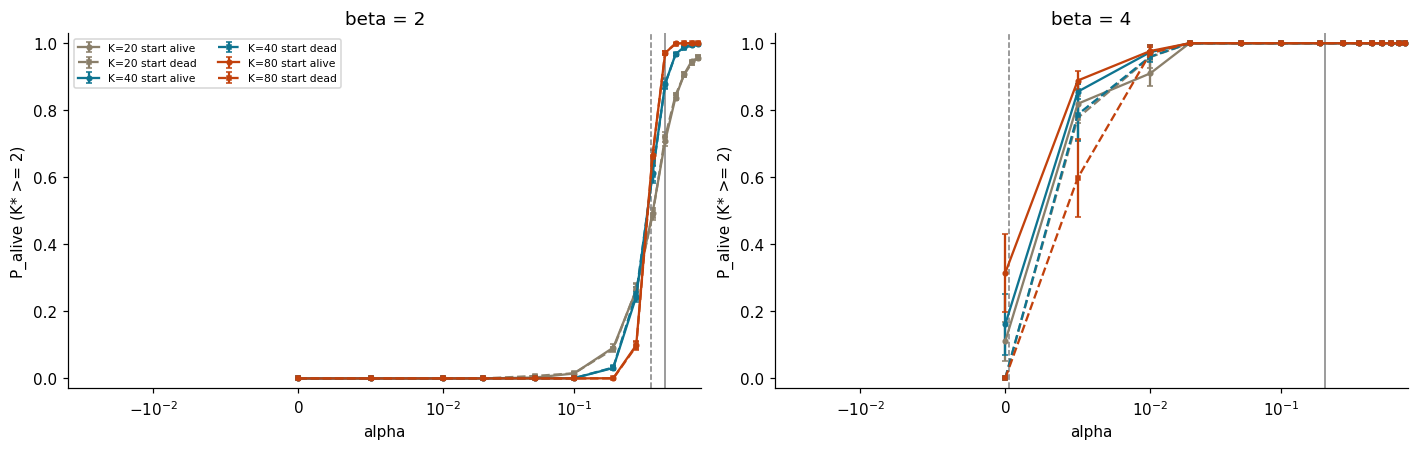

beta=2
  K= 20 alive-start  [0.   0.   0.   0.   0.   0.01 0.09 0.26 0.49 0.71 0.84 0.91 0.95 0.96]
  K= 20 dead-start   [0.   0.   0.   0.   0.01 0.02 0.09 0.27 0.49 0.72 0.84 0.91 0.94 0.96]
  K= 40 alive-start  [0.   0.   0.   0.   0.   0.   0.03 0.24 0.61 0.88 0.97 0.99 1.   1.  ]
  K= 40 dead-start   [0.   0.   0.   0.   0.   0.   0.03 0.25 0.61 0.88 0.97 0.99 0.99 1.  ]
  K= 80 alive-start  [0.   0.   0.   0.   0.   0.   0.   0.1  0.67 0.97 1.   1.   1.   1.  ]
  K= 80 dead-start   [0.   0.   0.   0.   0.   0.   0.   0.1  0.66 0.97 1.   1.   1.   1.  ]
beta=4
  K= 20 alive-start  [0.11 0.82 0.91 1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.  ]
  K= 20 dead-start   [0.   0.78 0.96 1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.  ]
  K= 40 alive-start  [0.16 0.86 0.97 1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.  ]
  K= 40 dead-start   [0.   0.79 0.96 1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.  ]
  K= 80 alive-start  [0.31 0.89 0.98 1.   1.   1.   1.  

In [4]:
z = np.load('data/sweep_K.npz')
Ks, betas, alphas = z['Ks'], z['betas'], z['alphas']
P = z['p_alive']                       # (K, beta, alpha, start, seed)
cols = {20: '#8a7f6a', 40: '#0e7490', 80: '#c2410c'}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for bi, b in enumerate(betas):
    for ki, K in enumerate(Ks):
        for si, ls in zip([1, 0], ['-', '--']):
            m = P[ki, bi, :, si].mean(-1)
            se = P[ki, bi, :, si].std(-1) / np.sqrt(P.shape[-1])
            ax[bi].errorbar(alphas, m, se, color=cols[int(K)], ls=ls, marker='o' if si else 's', ms=3, capsize=2,
                            label=f'K={int(K)} start {"alive" if si else "dead"}')
    ax[bi].axvline(edge(b, 0.0), color='grey', lw=1); ax[bi].axvline(edge(b, 1.0), color='grey', lw=1, ls='--')
    ax[bi].set_xscale('symlog', linthresh=0.01)
    ax[bi].set(xlabel='alpha', ylabel='P_alive (K* >= 2)', title=f'beta = {b:g}', ylim=(-0.03, 1.03))
ax[0].legend(fontsize=7, ncol=2)
fig.tight_layout(); fig.savefig(FIG / 'nb02_sweep_K.png'); plt.show()

for bi, b in enumerate(betas):
    print(f'beta={b:g}')
    for ki, K in enumerate(Ks):
        print(f'  K={int(K):3d} alive-start ', np.round(P[ki, bi, :, 1].mean(-1), 2))
        print(f'  K={int(K):3d} dead-start  ', np.round(P[ki, bi, :, 0].mean(-1), 2))
print('alphas', alphas)

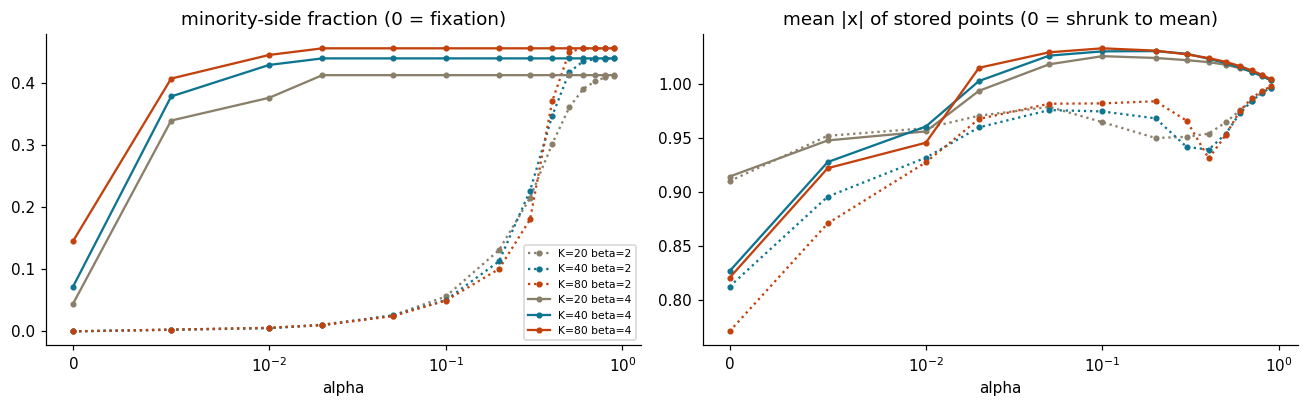

In [5]:
# what kind of death: fixation onto one side (minority -> 0) or shrinkage to the mean (size -> 0)?
Mi, Sz = z['minority'], z['size']
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for bi, b in enumerate(betas):
    for ki, K in enumerate(Ks):
        ax[0].plot(alphas, Mi[ki, bi, :, 1].mean(-1), marker='o', ms=3, color=cols[int(K)], ls='-' if bi else ':', label=f'K={int(K)} beta={b:g}')
        ax[1].plot(alphas, Sz[ki, bi, :, 1].mean(-1), marker='o', ms=3, color=cols[int(K)], ls='-' if bi else ':')
for a, t in zip(ax, ['minority-side fraction (0 = fixation)', 'mean |x| of stored points (0 = shrunk to mean)']):
    a.set_xscale('symlog', linthresh=0.01); a.set(xlabel='alpha', title=t)
ax[0].legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / 'nb02_death_kind.png'); plt.show()

## Reading

1. **beta = 2: a true transition.** The P_alive curves steepen with K and cross near **alpha_c ~ 0.4**. At alpha = 0.3 / 0.4 / 0.5, K = 20 gives 0.26 / 0.49 / 0.71 and K = 80 gives 0.10 / 0.67 / 0.97. The two-population mean field puts the edges at 0.39 (keep) and 0.50 (revive). That is close.
2. **No hysteresis in the simulation**, at either beta. Dead and alive starts give the same curves, apart from a small gap at beta = 4, K = 80, alpha = 0.005. The mean-field bistability is still an artifact. At beta = 4 the mean field says a dead bank needs alpha > 0.22 to revive, but the simulation revives at alpha = 0.005: a few full-size fresh points open their own basins.
3. **The dead phase is consensus (fixation), not shrinkage.** Below alpha_c the stored points keep |x| ~ 0.97 while the minority side empties (`nb02_death_kind.png`). The transition breaks a symmetry: two symmetric basins at high alpha, one side at low alpha. The right order parameter is the side imbalance p, not the size m.
4. **beta = 4: alpha_c is tiny** (~0.005), below this grid's resolution.

Hypothesis for the next test, not yet tested: at high beta attention COPIES one pattern (voter model; with noise, Kirman's ant model, alpha_c ~ 1/K), and at low beta it AVERAGES (majority rule / mean-field Ising, alpha_c finite). Prediction: alpha_c * K is constant at high beta, and alpha_c is constant at low beta.